In [2]:
import pandas as pd
import numpy as np
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report
from sklearn.ensemble import RandomForestClassifier

#incarcare set date proof of concept
df = pd.read_csv('../data/mock_data.csv')

print("- Validare date initiale -")
print(f"Dimensiune set date: {df.shape[0]} randuri, {df.shape[1]} coloane")
print("Valori lipsa per coloana:", df.isnull().sum())

#preprocessing (encoding )
df_encoded = pd.get_dummies(df, columns=['scenario'], drop_first=True)

X= df_encoded.drop(columns=['user_id', 'decision_abandon'])
y= df_encoded['decision_abandon']

#am folosit stratificare si am impartit datele in train si test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f"\nSet antrenare: {X_train.shape[0]} esantioane | Set test: {X_test.shape[0]} esantioane")

#antrenam modelul random forest
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

#evaluare model pe set de test
y_pred = rf_model.predict(X_test)

print("\n--- Evaluare model Random Forest ---")
print(f"acuratete (accuracy): {accuracy_score(y_test, y_pred):.2f}")
print("\nRaport clasificare (Precision / Recall / F1-Score):\n")
print(classification_report(y_test, y_pred))

- Validare date initiale -
Dimensiune set date: 15 randuri, 12 coloane
Valori lipsa per coloana: user_id                     0
scenario                    0
tech_experience             0
baseline_ai_trust           0
perceived_intrusiveness     0
perceived_transparency      0
perceived_authenticity      0
spoof_alert_present         0
task_completion_time_sec    0
error_made                  0
decision_abandon            0
ai_anxiety_score            0
dtype: int64

Set antrenare: 12 esantioane | Set test: 3 esantioane

--- Evaluare model Random Forest ---
acuratete (accuracy): 1.00

Raport clasificare (Precision / Recall / F1-Score):

              precision    recall  f1-score   support

           0       1.00      1.00      1.00         1
           1       1.00      1.00      1.00         2

    accuracy                           1.00         3
   macro avg       1.00      1.00      1.00         3
weighted avg       1.00      1.00      1.00         3



C:\Users\Administrator\AppData\Local\Temp\ipykernel_7016\4215238606.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=importances.values, y=importances.index, palette='viridis')


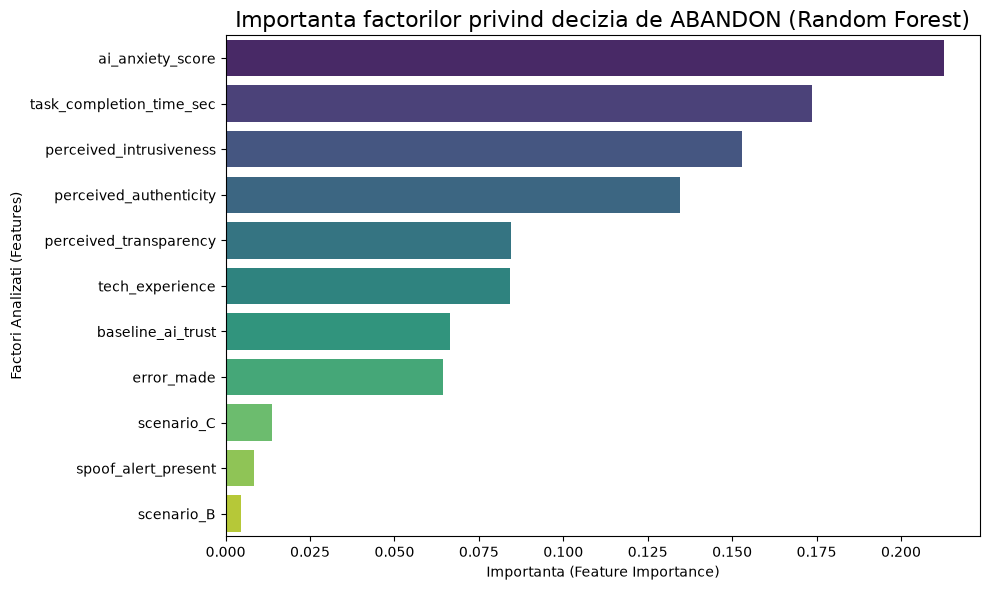

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

importances = pd.Series(rf_model.feature_importances_, index=X.columns).sort_values(ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x=importances.values, y=importances.index, palette='viridis')

plt.title('Importanta factorilor privind decizia de ABANDON (Random Forest)', fontsize=16)
plt.xlabel('Importanta (Feature Importance)', fontsize=10)
plt.ylabel('Factori Analizati (Features)', fontsize=10)
plt.tight_layout()

plt.show()